# nb04 · L3 无序结构：短程序（L3a）与中程序（L3b）

**目的**（`validation_methods_L0-L5.md` L3）：比较液态与非晶的局域结构，以及 RDF/ADF 看不到、
但会改变晶化行为的中程误差。

L3a（短程与化学序）：
1. 六种 partial RDF 及峰位、峰高、峰宽、第一极小值；
2. 物种分辨 ADF；
3. Ge/Sb/Te 配位数**完整分布**（不只是均值）；
4. 同极键比例；
5. Ge 四面体序参量分布；
6. 1-Wasserstein 与 Jensen–Shannon 距离。

L3b（中程与拓扑）：
1. 环尺寸分布；
2. 四元环比例与平面度；
3. ALTBC；
4. S(q) 与 FSDP。

> **L3 的核心纪律**：每个 state point 的键截断从 AIMD partial RDF 第一极小值得到，
> 然后对 AIMD 与 MLIP-MD **同时冻结**。本 notebook 里这条不是靠自觉——
> `StructureParams` 是一个显式对象，两侧分析函数吃的是同一个实例。

参考是 phase-1 的 canonical AIMD 链：每个状态点 **3 条独立副本**（306 原子、0.0309 at/Å³），MLIP 种子 k 与副本 k+1 配对。副本之间的差异给出 `sigma_ref`，所以 L3 第一次可以出 A/B/C 正式等级（第 6 节）。

In [1]:
import os
# per-model results/data (results/models/<key>/); without it mlipeval falls back to the
# flat pre-2026-09 layout, which no longer holds current results
os.environ.setdefault("MLIPEVAL_MODEL", "mace_mpa0")
import sys, json
sys.path.insert(0, "../scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlipeval import datasets, paths, protocols
from mlipeval.l3a_short_range import analyse_short_range, freeze_params_from_reference, sample_distances
from mlipeval.l3b_medium_range import (
    altbc, analyse_medium_range, fsdp, king_rings, principal_peak,
    ring_statistics, structure_factor_direct,
)
from mlipeval.neighbors import all_pairs, pair_key
from mlipeval.plotting import pair_color, species_color, use_style
from mlipeval.state_points import (
    CUTOFF_STATE, STATES, frozen_params, get_state, production_segments, reference_trajectory,
)
from mlipeval.thermo import infer_timestep, temperature_series

use_style()
pd.set_option("display.width", 210)
pd.set_option("display.max_colwidth", 60)

## 1. 状态点配对：把"同条件"这件事钉死

L3 比较的前提是 AIMD 段与 MLIP 段除了引擎之外**完全相同**：同一起始构型、同一盒子与密度、
同一温度、同一时间步。这个配对表放在 `mlipeval.state_points`，任何一次比较都从它取数据。

In [2]:
display(pd.DataFrame([{
    "state": s.name, "参考链": s.reference, "T (K)": s.temperature_k,
    "T_end (K)": s.temperature_end_k, "MLIP 步数": s.default_steps, "取样间隔": s.sample_every,
    "生产段": "整条程序" if s.is_ramp else f"末 {1 - s.equilibration_fraction:.0%}",
    "AIMD 副本": s.n_replicas, "MLIP 种子": s.available_seeds(), "用于": s.used_by,
} for s in STATES.values()]))

,state,参考链,T (K),T_end (K),MLIP 步数,取样间隔,生产段,AIMD 副本,MLIP 种子,用于
0,canon_amorphous_300K,canon:H4_melt_quench:nvt_300K,300.0,NaN,10000,15,末 50%,3,"[0, 1, 2]",L3a/L3b
1,canon_liquid_1200K,canon:H4_melt_quench:nvt_1200K,1200.0,NaN,10000,5,末 75%,3,"[0, 1, 2]",L3a/L3b and L4
2,canon_liquid_950K,canon:H3_md950:equil_950K+prod_950K,950.0,NaN,8333,5,末 60%,3,"[0, 1, 2]",L3a/L3b and L4
3,canon_quench,canon:H4_melt_quench:quench_1200_300K,1200.0,300.0,20000,10,整条程序,3,"[0, 1, 2]",L5
4,canon_liquid_3000K,canon:H4_melt_quench:melt_3000K,3000.0,NaN,3000,5,末 75%,3,"[0, 1, 2]",L3a/L3b and L4
5,canon_heating,canon:H3_heating:heating_300_1200K,300.0,1200.0,8333,10,整条程序,3,"[0, 1, 2]",L5


### 参考轨迹的温度：读得到，也要测一遍

canonical 链是本项目自己用 VASP 跑的，INCAR 里的温度程序是读得到的。这里仍然从轨迹直接**测**动能温度，
作为独立核对——它同时证明 MLIP 侧照抄的程序与参考实际走过的程序一致。

`mlipeval.thermo` 用相邻帧的中心差分速度测动能温度：

$$T=\frac{1}{3Nk_B}\sum_i m_i|v_i|^2,\qquad v_i\approx\frac{r_i(t+\Delta t)-r_i(t-\Delta t)}{2\Delta t}$$

先用**有** OSZICAR 的 phase-1 H0 preflight 验证这个测量本身。

In [3]:
from mlipeval.io_vasp import read_oszicar_md

rows = []
for name in ("nvt_1200K", "nvt_3000K", "nve_1200K"):
    traj = datasets.preflight(name)
    est = temperature_series(traj)
    _, t_oszicar = read_oszicar_md(paths.PHASE1 / datasets.PREFLIGHT[name] / "OSZICAR")
    rows.append({"H0 段": name, "OSZICAR T (K)": float(t_oszicar.mean()),
                 "从轨迹反推 (K)": est.mean, "比值": est.mean / float(t_oszicar.mean())})
display(pd.DataFrame(rows).round(3))
print("误差 0.2-2%，来源是中心差分对简谐模式的 sinc 低估（dt=3 fs 时 <1%）。")

,H0 段,OSZICAR T (K),从轨迹反推 (K),比值
0,nvt_1200K,1185.373,1160.781,0.979
1,nvt_3000K,3027.269,3024.271,0.999
2,nve_1200K,1219.096,1215.533,0.997


误差 0.2-2%，来源是中心差分对简谐模式的 sinc 低估（dt=3 fs 时 <1%）。


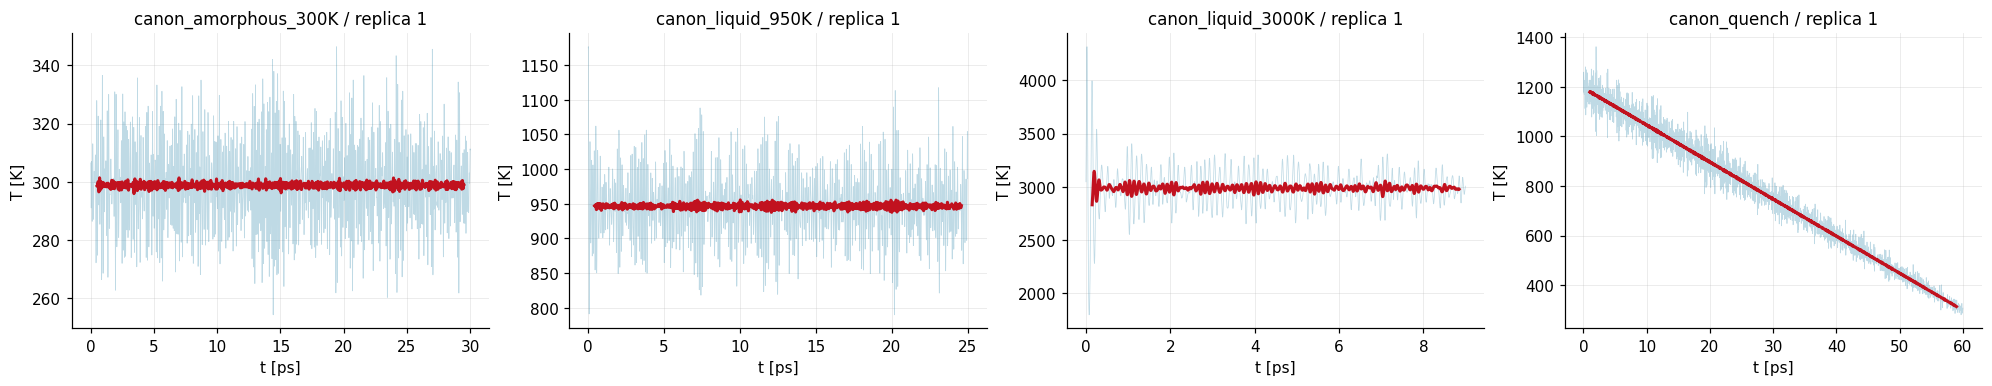

,state,INCAR 程序 (K),平均 T (K),std (K),前后半程漂移 (K),反推时间步 (fs)
0,canon_amorphous_300K,300,298.803,13.784,0.004,2.994
1,canon_liquid_950K,950,946.512,46.467,0.471,2.994
2,canon_liquid_3000K,3000,2988.178,189.522,0.751,2.994
3,canon_quench,1200 -> 300,747.139,261.283,-448.349,NaN


In [4]:
panels = [("canon_amorphous_300K", 300.0), ("canon_liquid_950K", 950.0),
          ("canon_liquid_3000K", 3000.0), ("canon_quench", None)]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
summary = []
for ax, (name, target) in zip(axes, panels):
    st = get_state(name)
    traj = reference_trajectory(st, replica=1, stride=1)   # every MD step: the velocity needs dt = 3 fs
    series = temperature_series(traj)
    t_ps = series.time_fs / 1000.0
    win = max(1, len(series.temperature) // 60)
    smooth = np.convolve(series.temperature, np.ones(win) / win, mode="same")
    ax.plot(t_ps, series.temperature, lw=0.5, alpha=0.3, color="#2e86ab")
    ax.plot(t_ps[win:-win], smooth[win:-win], lw=2.0, color="#c1121f")
    ax.set_title(f"{name} / replica 1"); ax.set_xlabel("t [ps]"); ax.set_ylabel("T [K]")
    row = {"state": name, "INCAR 程序 (K)": f"{st.temperature_k:.0f}" + (
               f" -> {st.temperature_end_k:.0f}" if st.is_ramp else ""),
           "平均 T (K)": series.mean, "std (K)": series.std,
           "前后半程漂移 (K)": series.half_to_half_drift}
    if target:
        row["反推时间步 (fs)"] = infer_timestep(traj, target)["implied_timestep_fs"]
    summary.append(row)
plt.show()
display(pd.DataFrame(summary).round(3))

（读图结论在执行后填写。）

## 2. 冻结分析参数：键截断怎么定

从 AIMD 的 partial RDF 取第一极小值。这一步比想象中难：原始直方图有噪声，
"第一个不再下降的点"这种朴素判据会在峰肩上就触发（早期版本给出 Ge–Te 截断 2.81 Å，
**小于**峰位 2.84 Å，明显错误）。

现在的做法：Savitzky–Golay 平滑（窗口 0.25 Å）→ 定峰 → 在峰后用 `find_peaks` 找**第一个有显著
prominence 的极小**。同时报告 `depth = (g_peak − g_min)/g_peak`：极小不够深就说明这个 partial
在该温度下根本没有良定义的第一极小，此时回退到**总** RDF 的第一极小，并把回退这件事记录下来。

In [5]:
state = "canon_amorphous_300K"
st = get_state(state)
segments = production_segments(state)            # replica 1 <-> seed 0
reference, model = segments["reference"], segments["model"]
print("参考:", json.dumps(reference.describe(), ensure_ascii=False))
print("模型:", json.dumps(model.describe(), ensure_ascii=False))

# frozen_params pools the production windows of all three replicas, with the
# state point's peak rule -- the same call run_l3 / run_l5 make
params, rdf_seed = frozen_params(state)
diag = pd.DataFrame(params.cutoff_diagnostics).T
diag["cutoff (A)"] = [params.bond_cutoffs.get(k, np.nan) for k in diag.index]
display(diag[["r_peak", "r_min", "depth", "well_defined", "source", "cutoff (A)"]].round(3))
print("\n参数来源:", params.provenance)

参考: {"name": "aimd_canon_amorphous_300K_r1[333:None:1]", "n_frames": 334, "n_atoms": 306, "composition": "Ge68Sb68Te170", "volume_A3": 9902.9123, "number_density_at_per_A3": 0.0309, "timestep_fs": 3.0, "sample_stride": 15, "protocol_id": "gst225_aimd_canonical_v1:H4_mq_s01_04_nvt300", "source": "$MLIPEVAL_WORKSPACE/phase1_vasp_inputs_20260828/H4_mq_s01_04_nvt300/runs/run_3kFlO4qNgB/XDATCAR"}
模型: {"name": "mlip_canon_amorphous_300K[333:None:1]", "n_frames": 334, "n_atoms": 306, "composition": "Ge68Sb68Te170", "volume_A3": 9902.9123, "number_density_at_per_A3": 0.0309, "timestep_fs": 3.0, "sample_stride": 15, "protocol_id": "mlip_md_canon_amorphous_300K_seed0", "source": "$MLIPEVAL_WORKSPACE/eval_framework/data/models/mace_mpa0/md_canon_amorphous_300K__lammps.npz"}


,r_peak,r_min,depth,well_defined,source,cutoff (A)
_total,2.8875,3.5375,0.704141,True,NaN,NaN
Ge-Ge,2.6375,3.1625,0.446168,True,partial RDF first minimum,3.163
Ge-Sb,2.7875,3.2125,0.609805,True,partial RDF first minimum,3.213
Ge-Te,2.7875,4.4875,0.87336,False,fallback: total RDF first minimum (partial minimum ill-d...,3.538
Sb-Sb,2.9625,3.4625,0.782881,True,partial RDF first minimum,3.463
Sb-Te,2.9375,3.8875,0.843816,True,partial RDF first minimum,3.888
Te-Te,2.9125,3.1875,0.299949,True,partial RDF first minimum,3.188



参数来源: first minimum of the partial RDF of 'aimd_canon_amorphous_300K_pooled' (protocol_id=gst225_aimd_canonical_v1:H4_mq_s01_04_nvt300, 1002 frames, stride=1, search window 1.8-4.5 A, peak_rule=first)


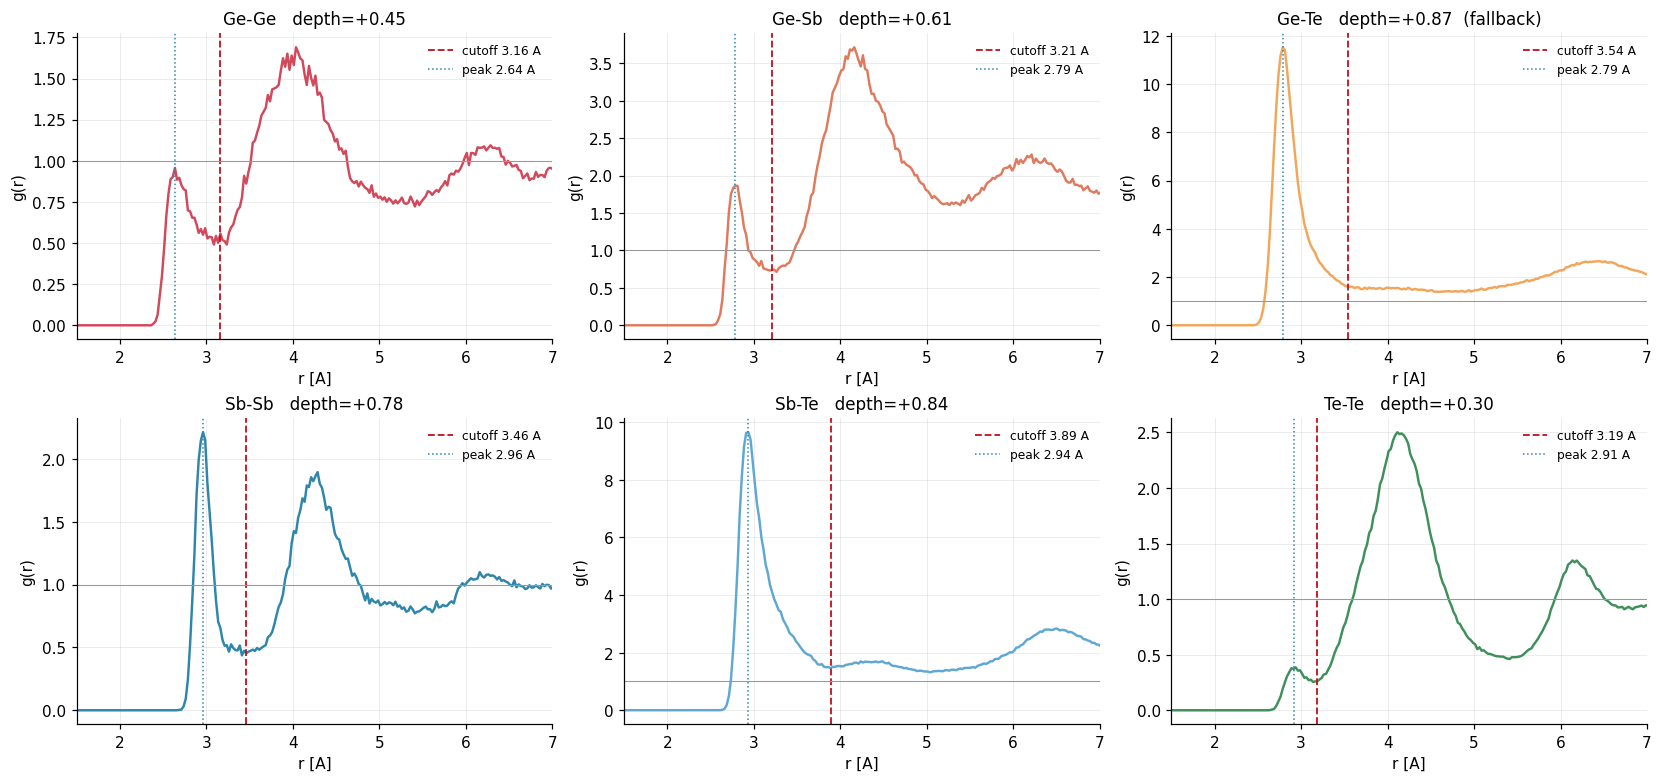

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
r = rdf_seed["r"]
for ax, (a, b) in zip(axes.flat, all_pairs(reference.species)):
    key = pair_key(a, b)
    ax.plot(r, rdf_seed[key], color=pair_color(key), lw=1.6)
    info = params.cutoff_diagnostics[key]
    ax.axvline(params.bond_cutoffs[key], color="#c1121f", ls="--", lw=1.2,
               label=f"cutoff {params.bond_cutoffs[key]:.2f} A")
    if np.isfinite(info.get("r_peak", np.nan)):
        ax.axvline(info["r_peak"], color="#2e86ab", ls=":", lw=1.0, label=f"peak {info['r_peak']:.2f} A")
    ax.axhline(1.0, color="#999", lw=0.7)
    ax.set_xlim(1.5, 7.0); ax.set_title(f"{key}   depth={info['depth']:+.2f}"
                                        + ("" if info["well_defined"] else "  (fallback)"))
    ax.set_xlabel("r [A]"); ax.set_ylabel("g(r)"); ax.legend(fontsize=8)
plt.show()

## 3. L3a：短程序与化学序

下面这一个调用把 L3a 的六项全部跑完，AIMD 与 MLIP 两侧共用同一个 `params`。
这里展示的是副本 1 ↔ 种子 0 这一对；三对合起来的判级见第 6 节。

In [7]:
l3a = analyse_short_range(reference, params, model_traj=model, stride=st.l3_stride,
                          model_stride=st.l3_stride, state_label=state)
print(f"L3a 产出 {len(l3a.results)} 条 metric")

L3a 产出 52 条 metric


### 3.1 六种 partial RDF

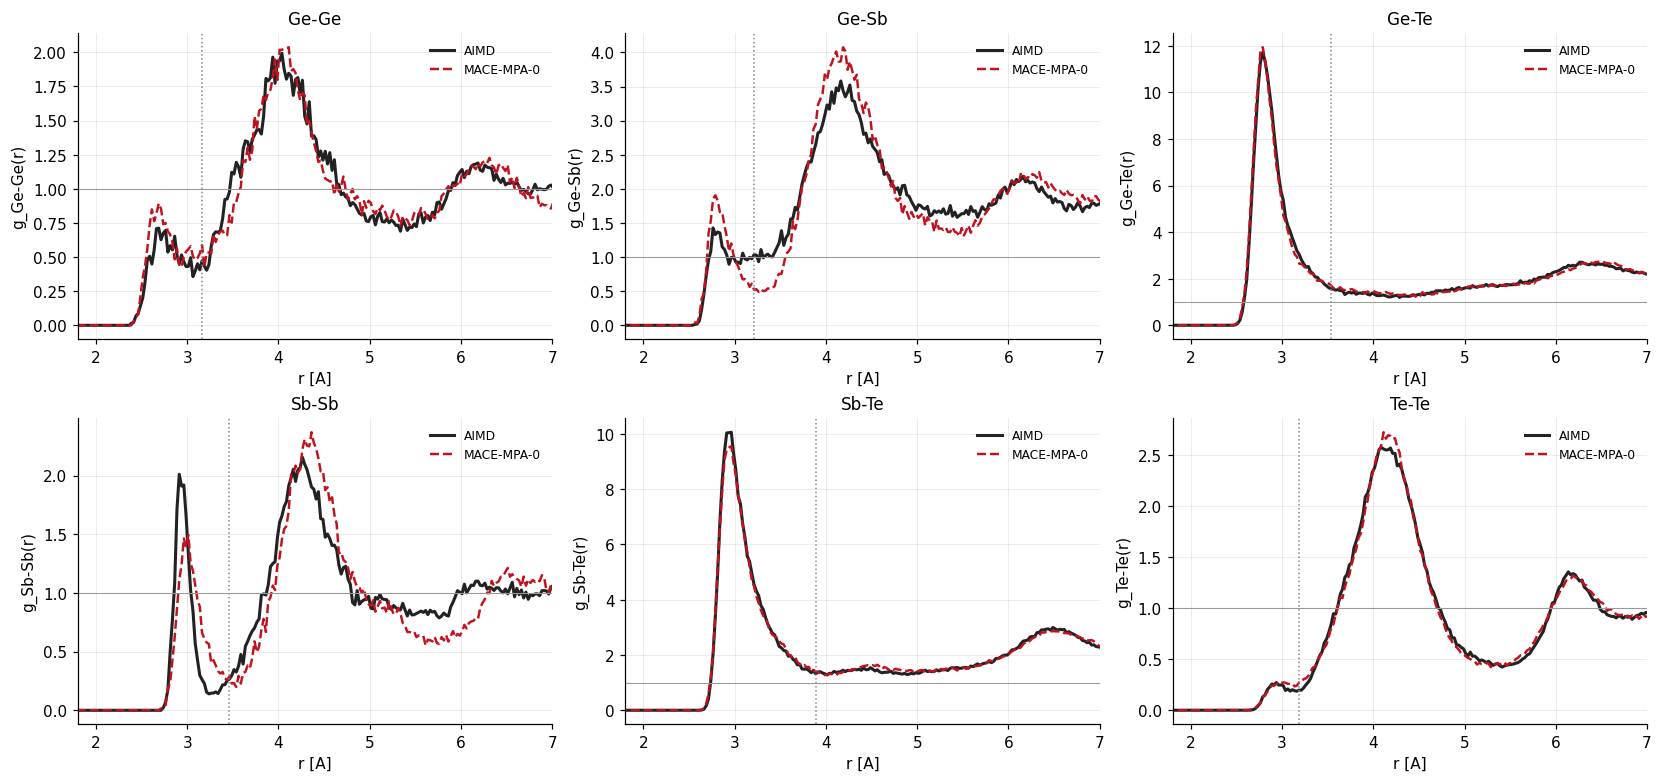

,AIMD r_peak,MLIP r_peak,Δr_peak,AIMD g_peak,MLIP g_peak,AIMD fwhm,MLIP fwhm
Ge-Ge,4.0375,4.1125,0.075,1.9933,2.0371,NaN,NaN
Ge-Sb,4.1625,4.1875,0.025,3.5811,4.0762,NaN,NaN
Ge-Te,2.7875,2.7875,0.000,11.7216,11.9423,0.325,0.325
Sb-Sb,4.2625,4.3625,0.100,2.1569,2.3701,NaN,NaN
Sb-Te,2.9625,2.9625,0.000,10.0558,9.5535,0.375,0.400
Te-Te,4.0875,4.1125,0.025,2.5730,2.7214,NaN,NaN


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
r = l3a.rdf_ref["r"]
for ax, (a, b) in zip(axes.flat, all_pairs(reference.species)):
    key = pair_key(a, b)
    ax.plot(r, l3a.rdf_ref[key], color="#222222", lw=2.0, label="AIMD")
    ax.plot(r, l3a.rdf_model[key], color="#c1121f", lw=1.6, ls="--", label="MACE-MPA-0")
    ax.axvline(params.bond_cutoffs[key], color="#888", ls=":", lw=1.0)
    ax.axhline(1.0, color="#999", lw=0.7)
    ax.set_xlim(1.8, 7.0); ax.set_xlabel("r [A]"); ax.set_ylabel(f"g_{key}(r)")
    ax.set_title(key); ax.legend(fontsize=8)
plt.show()

peaks = pd.DataFrame({
    key: {"AIMD r_peak": l3a.peaks_ref[key]["r_peak"], "MLIP r_peak": l3a.peaks_model[key]["r_peak"],
          "Δr_peak": l3a.peaks_model[key]["r_peak"] - l3a.peaks_ref[key]["r_peak"],
          "AIMD g_peak": l3a.peaks_ref[key]["g_peak"], "MLIP g_peak": l3a.peaks_model[key]["g_peak"],
          "AIMD fwhm": l3a.peaks_ref[key]["fwhm"], "MLIP fwhm": l3a.peaks_model[key]["fwhm"]}
    for key in l3a.peaks_ref
}).T
display(peaks.round(4))

### 3.2 键角分布（ADF）

GST 非晶的角分布有两个特征峰：~90° 的八面体/缺陷八面体成分，和 ~109° 的四面体成分。
它们的相对权重决定了 Ge 的成键性质，是 MLIP 最容易画错的地方之一。

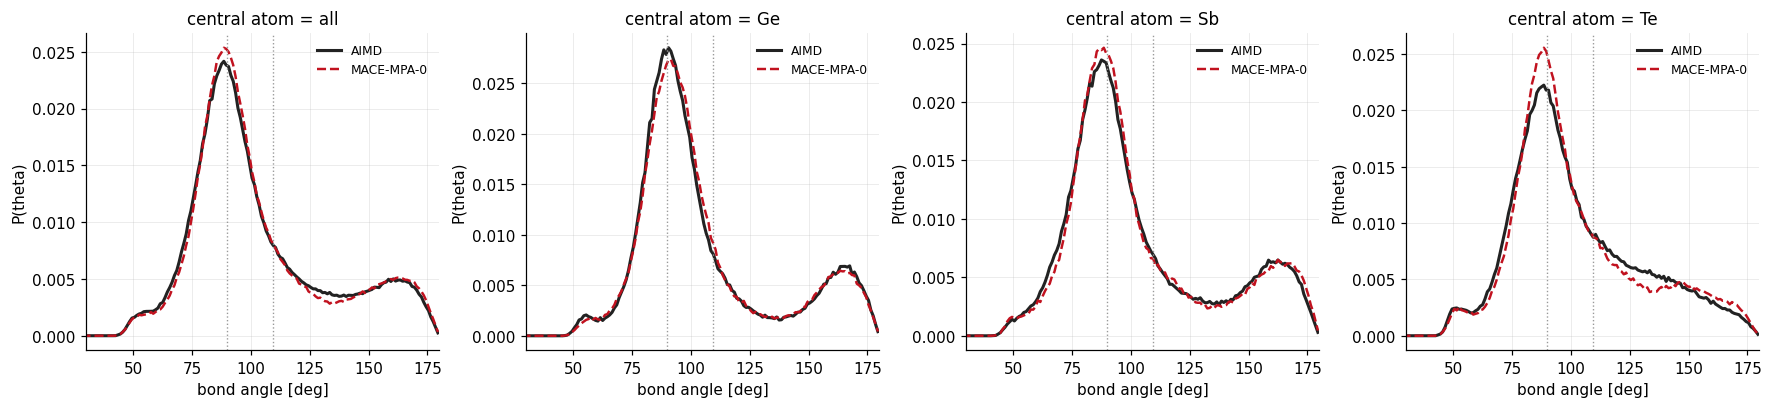

,metric_id,value,unit
0,L3a.adf.Ge.jensen_shannon@canon_amorphous_300K,0.03516,-
1,L3a.adf.Ge.wasserstein1@canon_amorphous_300K,0.59971,deg
2,L3a.adf.Sb.jensen_shannon@canon_amorphous_300K,0.03983,-
3,L3a.adf.Sb.wasserstein1@canon_amorphous_300K,0.66748,deg
4,L3a.adf.Te.jensen_shannon@canon_amorphous_300K,0.05904,-
5,L3a.adf.Te.wasserstein1@canon_amorphous_300K,1.29748,deg
6,L3a.adf.all.jensen_shannon@canon_amorphous_300K,0.03353,-
7,L3a.adf.all.wasserstein1@canon_amorphous_300K,0.72756,deg


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
angle = l3a.adf_ref["angle"]
for ax, key in zip(axes, ["all"] + list(reference.species)):
    ax.plot(angle, l3a.adf_ref[key], color="#222222", lw=2.0, label="AIMD")
    ax.plot(angle, l3a.adf_model[key], color="#c1121f", lw=1.6, ls="--", label="MACE-MPA-0")
    for ref_angle, name in ((90.0, "90°"), (109.47, "109.5°")):
        ax.axvline(ref_angle, color="#999", ls=":", lw=0.9)
    ax.set_xlim(30, 180); ax.set_xlabel("bond angle [deg]"); ax.set_ylabel("P(theta)")
    ax.set_title(f"central atom = {key}"); ax.legend(fontsize=8)
plt.show()

adf_rows = [{"metric_id": r.metric_id, "value": r.value, "unit": r.unit}
            for r in l3a.results if ".adf." in r.metric_id]
display(pd.DataFrame(adf_rows).round(5))

### 3.3 配位数完整分布

框架特意写的是"配位数**完整分布**"，不是平均配位数——两个模型可以有相同的平均 CN
却有完全不同的分布形状（例如一个是纯 4 配位，一个是 3/5 配位各半）。
所以这里同时报告均值差和分布间的 Jensen–Shannon 距离。

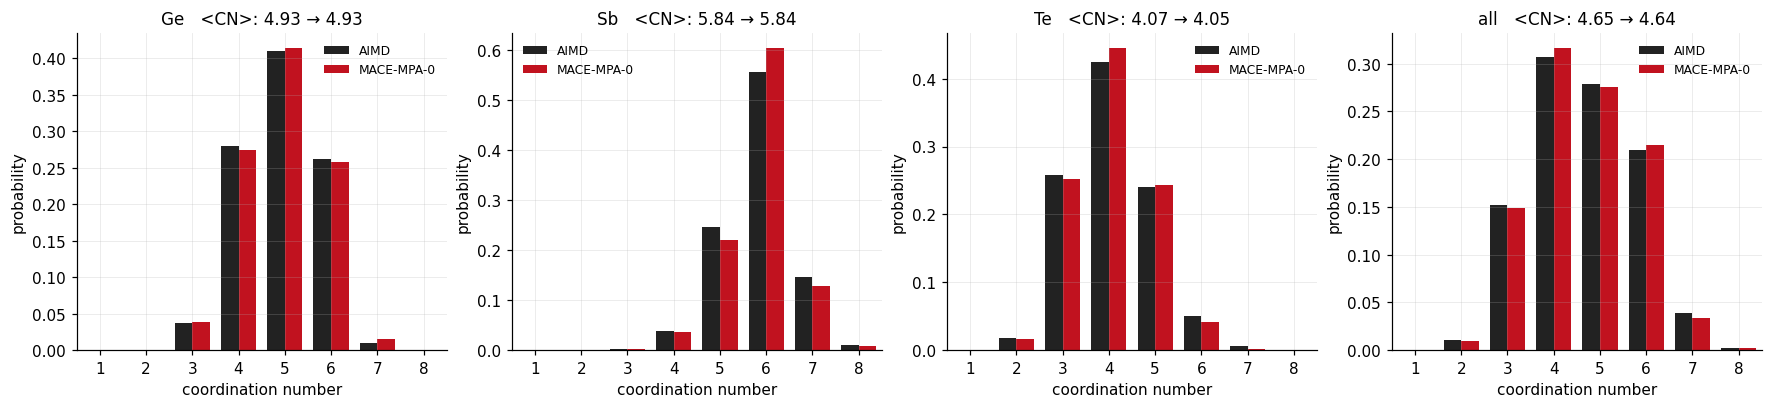

,metric_id,value,unit,reference
0,L3a.cn.Ge.mean@canon_amorphous_300K,4.9347,-,4.9278
1,L3a.cn.Ge.jensen_shannon@canon_amorphous_300K,0.0185,-,NaN
2,L3a.cn.Sb.mean@canon_amorphous_300K,5.8447,-,5.8395
3,L3a.cn.Sb.jensen_shannon@canon_amorphous_300K,0.0442,-,NaN
4,L3a.cn.Te.mean@canon_amorphous_300K,4.0480,-,4.0666
5,L3a.cn.Te.jensen_shannon@canon_amorphous_300K,0.0369,-,NaN
6,L3a.cn.all.mean@canon_amorphous_300K,4.6443,-,4.6520
7,L3a.cn.all.jensen_shannon@canon_amorphous_300K,0.0161,-,NaN


In [10]:
cn_values = l3a.cn_ref["cn_values"]
species_list = [s for s in l3a.cn_ref if s not in ("cn_values", "_meta")]
fig, axes = plt.subplots(1, len(species_list), figsize=(4 * len(species_list), 3.6))
width = 0.38
for ax, key in zip(np.atleast_1d(axes), species_list):
    ax.bar(cn_values - width / 2, l3a.cn_ref[key], width=width, color="#222222", label="AIMD")
    ax.bar(cn_values + width / 2, l3a.cn_model[key], width=width, color="#c1121f", label="MACE-MPA-0")
    mean_ref = float(np.sum(cn_values * l3a.cn_ref[key]))
    mean_mod = float(np.sum(cn_values * l3a.cn_model[key]))
    ax.set_xlim(0.5, 8.5); ax.set_xlabel("coordination number"); ax.set_ylabel("probability")
    ax.set_title(f"{key}   <CN>: {mean_ref:.2f} → {mean_mod:.2f}")
    ax.legend(fontsize=8)
plt.show()

display(pd.DataFrame([{"metric_id": r.metric_id, "value": r.value, "unit": r.unit,
                       "reference": (r.extra or {}).get("reference")}
                      for r in l3a.results if ".cn." in r.metric_id]).round(4))

### 3.4 同极键比例与 Ge 四面体序

- **同极键**（Ge–Ge / Sb–Sb / Te–Te）在化学计量 GST 里应当是少数派；比例明显偏高说明模型把化学序学松了。
- **Ge 四面体序参量** $q = 1-\frac{3}{8}\sum_{i<j}(\cos\theta_{ij}+\frac13)^2$：
  $q\to1$ 是理想四面体，$q\to0$ 是理想气体。a-GST 里 Ge 是八面体与四面体共存，
  $q>0.8$ 的比例是文献里常用的"四面体 Ge 占比"。

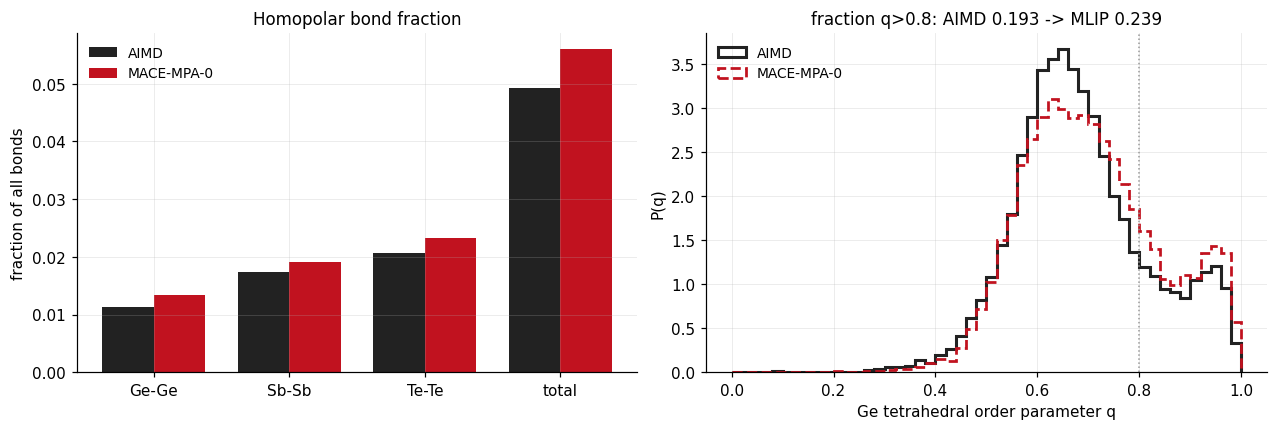

,metric_id,value,unit,reference
0,L3a.homopolar.Ge@canon_amorphous_300K,0.0135,fraction of bonds,0.0113
1,L3a.homopolar.Sb@canon_amorphous_300K,0.0192,fraction of bonds,0.0174
2,L3a.homopolar.Te@canon_amorphous_300K,0.0233,fraction of bonds,0.0207
3,L3a.homopolar.total@canon_amorphous_300K,0.0560,fraction of bonds,0.0493
4,L3a.tetrahedral_q.Ge.mean@canon_amorphous_300K,0.7055,-,0.6863
5,L3a.tetrahedral_q.Ge.wasserstein1@canon_amorphous_300K,0.0192,-,NaN


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
keys = [k for k in l3a.homopolar_ref if k != "total"] + ["total"]
x = np.arange(len(keys)); width = 0.38
axes[0].bar(x - width / 2, [l3a.homopolar_ref[k] for k in keys], width, color="#222222", label="AIMD")
axes[0].bar(x + width / 2, [l3a.homopolar_model[k] for k in keys], width, color="#c1121f", label="MACE-MPA-0")
axes[0].set_xticks(x); axes[0].set_xticklabels([f"{k}-{k}" if k != "total" else "total" for k in keys])
axes[0].set_ylabel("fraction of all bonds"); axes[0].set_title("Homopolar bond fraction"); axes[0].legend()

bins = np.linspace(0, 1, 51)
axes[1].hist(l3a.tetra_ref, bins=bins, density=True, histtype="step", lw=2.0, color="#222222", label="AIMD")
axes[1].hist(l3a.tetra_model, bins=bins, density=True, histtype="step", lw=1.8, ls="--",
             color="#c1121f", label="MACE-MPA-0")
axes[1].axvline(0.8, color="#999", ls=":", lw=1.0)
axes[1].set_xlabel("Ge tetrahedral order parameter q"); axes[1].set_ylabel("P(q)")
axes[1].set_title(f"fraction q>0.8: AIMD {np.mean(l3a.tetra_ref > 0.8):.3f} -> "
                  f"MLIP {np.mean(l3a.tetra_model > 0.8):.3f}")
axes[1].legend()
plt.show()

display(pd.DataFrame([{"metric_id": r.metric_id, "value": r.value, "unit": r.unit,
                       "reference": (r.extra or {}).get("reference")}
                      for r in l3a.results
                      if "homopolar" in r.metric_id or "tetrahedral" in r.metric_id]).round(4))

### 3.5 分布距离汇总

RDF 的峰位差是"点估计"，分布距离才刻画整条曲线的差异。这里用两种互补的度量：
**1-Wasserstein**（对峰位移动敏感，单位与横轴一致）和 **Jensen–Shannon**（对形状差异敏感，无量纲、有界）。

,metric_id,value,unit
0,L3a.rdf.Ge-Ge.wasserstein1,0.02837,A
1,L3a.rdf.Ge-Ge.jensen_shannon,0.04286,-
2,L3a.rdf.Ge-Sb.wasserstein1,0.02784,A
3,L3a.rdf.Ge-Sb.jensen_shannon,0.05737,-
4,L3a.rdf.Ge-Te.wasserstein1,0.01123,A
5,L3a.rdf.Ge-Te.jensen_shannon,0.02169,-
6,L3a.rdf.Sb-Sb.wasserstein1,0.04757,A
7,L3a.rdf.Sb-Sb.jensen_shannon,0.09004,-
8,L3a.rdf.Sb-Te.wasserstein1,0.01150,A
9,L3a.rdf.Sb-Te.jensen_shannon,0.01766,-


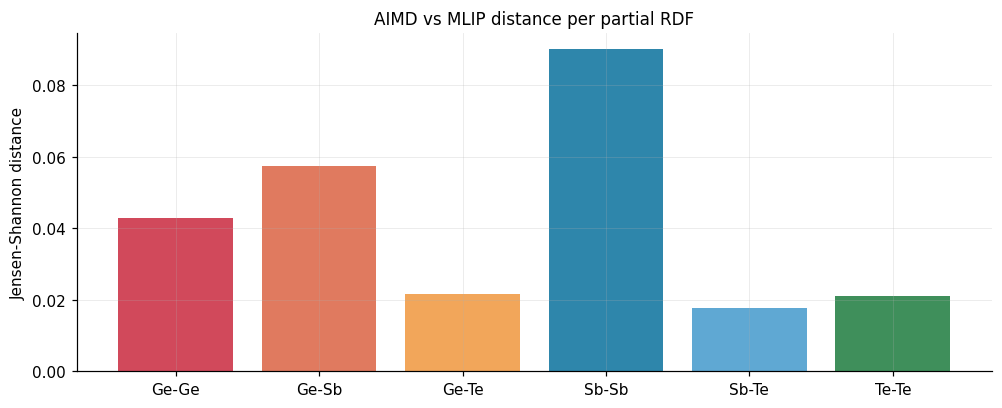

In [12]:
dist = pd.DataFrame([{
    "metric_id": r.metric_id.split("@")[0], "value": r.value, "unit": r.unit,
} for r in l3a.results if "wasserstein" in r.metric_id or "jensen_shannon" in r.metric_id])
display(dist.round(5))

fig, ax = plt.subplots(figsize=(9, 3.6))
rdf_js = dist[dist.metric_id.str.startswith("L3a.rdf.") & dist.metric_id.str.endswith("jensen_shannon")]
labels = [m.split(".")[2] for m in rdf_js.metric_id]
ax.bar(labels, rdf_js.value, color=[pair_color(l) for l in labels])
ax.set_ylabel("Jensen-Shannon distance"); ax.set_title("AIMD vs MLIP distance per partial RDF")
plt.show()

## 4. L3b：中程序与拓扑

### 环的定义必须先固定

框架要求"第一阶段只选一种 ring 算法，不同时维护多种实现"。这里实现的是
**King 最短路径判据**：对每个原子 $i$ 和它的每一对成键近邻 $(j,k)$，
找出绕开 $i$ 的最短 $j\to k$ 路径，与 $i$ 一起闭合成环；按节点集合去重，
并在 `max_ring_size` 处截断。换一种判据所有环数都会变，所以算法名与最大环尺寸
都写进 `StructureParams` 并回写到每条 metric。

In [13]:
l3b = analyse_medium_range(reference, params, model_traj=model,
                           stride=st.ring_stride, model_stride=st.ring_stride,
                           state_label=state, sq_stride=st.ring_stride)
print(f"环算法: {params.ring_algorithm}, 最大环尺寸: {params.max_ring_size}")
print(f"L3b 产出 {len(l3b.results)} 条 metric")

环算法: king-shortest-path, 最大环尺寸: 12
L3b 产出 18 条 metric


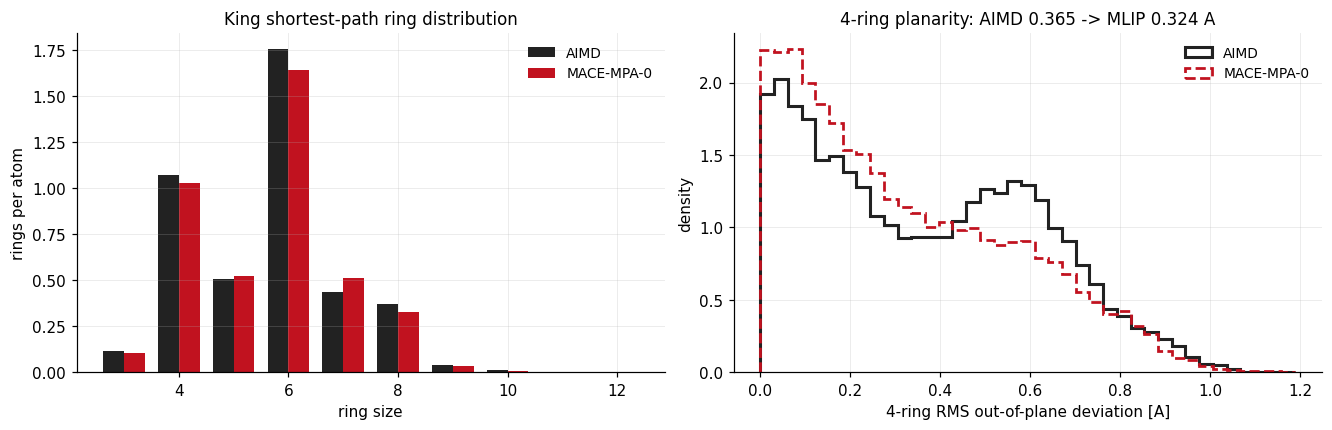

,metric_id,value,unit,reference
0,L3b.rings.size3,0.10312,rings/atom,0.11350
1,L3b.rings.size4,1.02941,rings/atom,1.07353
2,L3b.rings.size5,0.52282,rings/atom,0.50870
3,L3b.rings.size6,1.63930,rings/atom,1.75327
4,L3b.rings.size7,0.51021,rings/atom,0.43598
5,L3b.rings.size8,0.32972,rings/atom,0.37220
6,L3b.rings.size9,0.03338,rings/atom,0.03974
7,L3b.rings.size10,0.00502,rings/atom,0.01010
8,L3b.rings.size11,0.00012,rings/atom,0.00023
9,L3b.rings.size12,0.00000,rings/atom,0.00000


In [14]:
sizes = l3b.rings_ref["sizes"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
width = 0.38
axes[0].bar(sizes - width / 2, l3b.rings_ref["rings_per_atom"], width, color="#222222", label="AIMD")
axes[0].bar(sizes + width / 2, l3b.rings_model["rings_per_atom"], width, color="#c1121f", label="MACE-MPA-0")
axes[0].set_xlabel("ring size"); axes[0].set_ylabel("rings per atom")
axes[0].set_title("King shortest-path ring distribution"); axes[0].legend()

pl_ref, pl_mod = l3b.rings_ref["planarity_4ring"], l3b.rings_model["planarity_4ring"]
if pl_ref.size and pl_mod.size:
    bins = np.linspace(0, max(pl_ref.max(), pl_mod.max()), 40)
    axes[1].hist(pl_ref, bins=bins, density=True, histtype="step", lw=2.0, color="#222222", label="AIMD")
    axes[1].hist(pl_mod, bins=bins, density=True, histtype="step", lw=1.8, ls="--",
                 color="#c1121f", label="MACE-MPA-0")
    axes[1].set_xlabel("4-ring RMS out-of-plane deviation [A]"); axes[1].set_ylabel("density")
    axes[1].set_title(f"4-ring planarity: AIMD {pl_ref.mean():.3f} -> MLIP {pl_mod.mean():.3f} A")
    axes[1].legend()
plt.show()

display(pd.DataFrame([{"metric_id": r.metric_id.split("@")[0], "value": r.value, "unit": r.unit,
                       "reference": (r.extra or {}).get("reference")}
                      for r in l3b.results if "rings" in r.metric_id or "planarity" in r.metric_id]).round(5))

### ALTBC：Peierls 畸变

角度受限三体关联：对每个中心原子，取夹角落在 180° ± 25° 内的成键对，把两条键长
$(d_1,d_2)$ 打进二维直方图。GST 的 Peierls 畸变表现为权重偏离对角线（一短一长）；
把八面体过度对称化的模型会把密度堆到对角线上。`asymmetry` = 该分布上 $\langle|d_1-d_2|\rangle$。

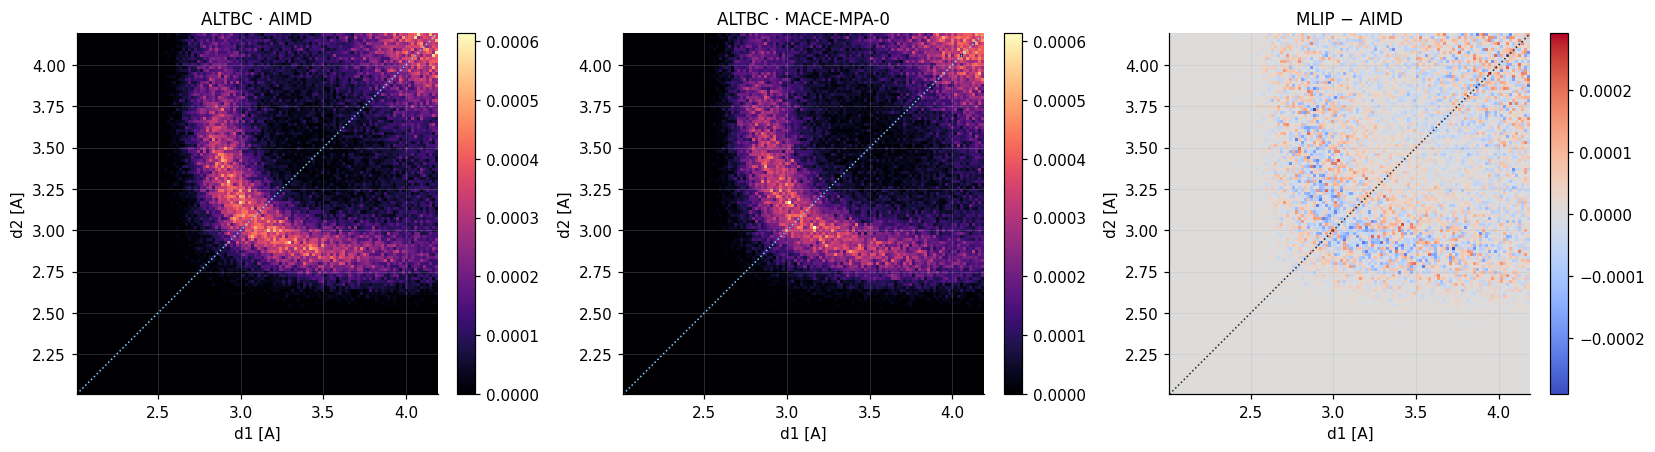

asymmetry <|d1-d2|>:  AIMD 0.5263 A  →  MLIP 0.5292 A


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
extent = [l3b.altbc_ref["r"][0], l3b.altbc_ref["r"][-1]] * 2
vmax = max(l3b.altbc_ref["hist"].max(), l3b.altbc_model["hist"].max())
for ax, (title, hist) in zip(axes[:2], [("AIMD", l3b.altbc_ref["hist"]),
                                        ("MACE-MPA-0", l3b.altbc_model["hist"])]):
    im = ax.imshow(hist.T, origin="lower", extent=extent, aspect="equal",
                   cmap="magma", vmin=0, vmax=vmax)
    ax.plot(extent[:2], extent[:2], color="#7fd1ff", lw=1.0, ls=":")
    ax.set_xlabel("d1 [A]"); ax.set_ylabel("d2 [A]"); ax.set_title(f"ALTBC · {title}")
    plt.colorbar(im, ax=ax, fraction=0.046)

diff = l3b.altbc_model["hist"] - l3b.altbc_ref["hist"]
lim = np.abs(diff).max()
im = axes[2].imshow(diff.T, origin="lower", extent=extent, aspect="equal",
                    cmap="coolwarm", vmin=-lim, vmax=lim)
axes[2].plot(extent[:2], extent[:2], color="#222", lw=1.0, ls=":")
axes[2].set_xlabel("d1 [A]"); axes[2].set_ylabel("d2 [A]"); axes[2].set_title("MLIP − AIMD")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.show()

print(f"asymmetry <|d1-d2|>:  AIMD {l3b.altbc_ref['asymmetry'][0]:.4f} A  →  "
      f"MLIP {l3b.altbc_model['asymmetry'][0]:.4f} A")

### S(q) 与 FSDP：为什么不能用 g(r) 的傅里叶变换

把截断在 $r_{max}=10$ Å 的 $g(r)-1$ 做傅里叶变换，在低 $q$ 是不可用的：
变换只在 $q\gtrsim 2\pi/r_{max}\approx0.63$ Å⁻¹ 才有意义，低于此处会出现大幅振荡，
甚至得到**负的 $S(q)$**（实测 $S(0.4)=6.7$、$S(0.7)=-0.6$）。

对周期盒子正确的做法是直接在盒子允许的倒格矢上求和：

$$S(q)=1+\frac{1}{\langle b\rangle^2}\left[\frac{1}{N}\left\langle\Big|\sum_j b_j e^{i\mathbf q\cdot\mathbf r_j}\Big|^2\right\rangle-\langle b^2\rangle\right]$$

盒子能表达的最小波矢是 $2\pi/L\approx0.29$ Å⁻¹（21.5 Å 的立方胞，306 原子、0.0309 at/Å³）。a-GST 的 FSDP 在 ~1 Å⁻¹，
离这个下限并不远——所以 FSDP 到底有没有被这个盒子分辨出来，必须**报告**而不是掩盖。

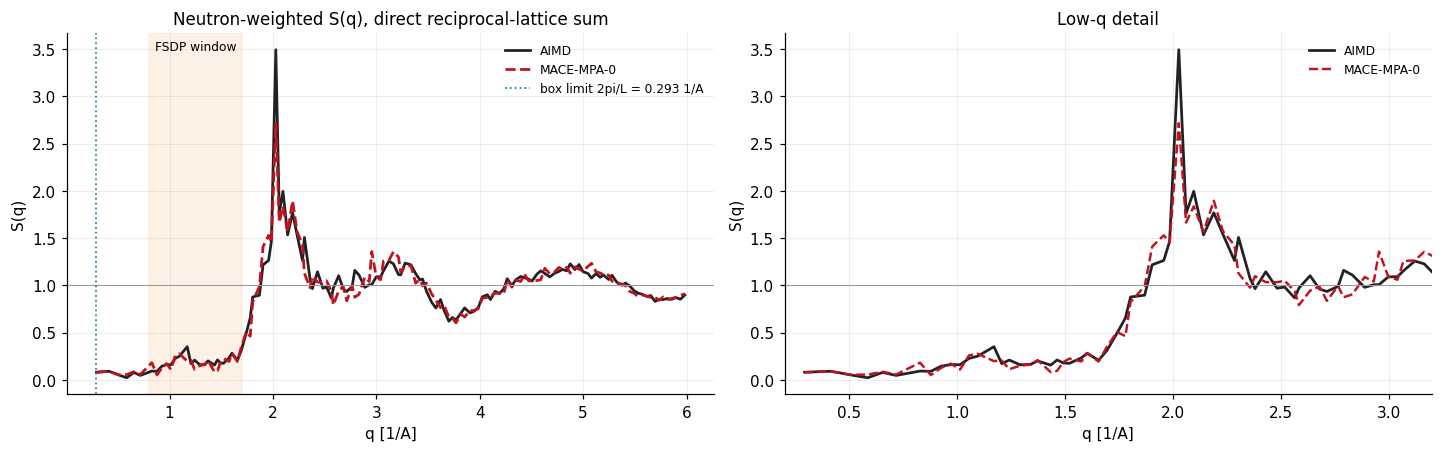

,q_fsdp,S_fsdp,fwhm,resolved,window,n_points_in_window,on_window_edge,below_box_resolution,q_pp,S_pp
AIMD,1.170358,0.350614,0.192818,True,"(0.8, 1.7)",21,False,False,2.02712,3.492573
MACE-MPA-0,1.693438,0.347803,NaN,False,"(0.8, 1.7)",21,True,False,2.02712,2.715565


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))
for ax, (q, S, label, color) in zip([axes[0]] * 2,
        [(l3b.sq_ref["q"], l3b.sq_ref["S"], "AIMD", "#222222"),
         (l3b.sq_model["q"], l3b.sq_model["S"], "MACE-MPA-0", "#c1121f")]):
    ax.plot(q, S, color=color, lw=1.8, ls="-" if label == "AIMD" else "--", label=label)
axes[0].axhline(1.0, color="#999", lw=0.7)
axes[0].axvline(l3b.sq_ref["q_min_accessible"], color="#2e86ab", ls=":", lw=1.2,
                label=f"box limit 2pi/L = {l3b.sq_ref['q_min_accessible']:.3f} 1/A")
axes[0].axvspan(0.8, 1.7, color="#f2a65a", alpha=0.15)
axes[0].text(1.25, axes[0].get_ylim()[1] * 0.95, "FSDP window", ha="center", fontsize=8)
axes[0].set_xlabel("q [1/A]"); axes[0].set_ylabel("S(q)")
axes[0].set_title("Neutron-weighted S(q), direct reciprocal-lattice sum"); axes[0].legend(fontsize=8)

axes[1].plot(l3b.sq_ref["q"], l3b.sq_ref["S"], color="#222222", lw=1.8, label="AIMD")
axes[1].plot(l3b.sq_model["q"], l3b.sq_model["S"], color="#c1121f", lw=1.6, ls="--", label="MACE-MPA-0")
axes[1].set_xlim(0.2, 3.2); axes[1].axhline(1.0, color="#999", lw=0.7)
axes[1].set_xlabel("q [1/A]"); axes[1].set_ylabel("S(q)"); axes[1].set_title("Low-q detail")
axes[1].legend(fontsize=8)
plt.show()

fs_ref = fsdp(l3b.sq_ref["q"], l3b.sq_ref["S"], q_min_accessible=l3b.sq_ref["q_min_accessible"])
fs_mod = fsdp(l3b.sq_model["q"], l3b.sq_model["S"], q_min_accessible=l3b.sq_model["q_min_accessible"])
pp_ref = principal_peak(l3b.sq_ref["q"], l3b.sq_ref["S"])
pp_mod = principal_peak(l3b.sq_model["q"], l3b.sq_model["S"])
display(pd.DataFrame({"AIMD": {**fs_ref, **pp_ref}, "MACE-MPA-0": {**fs_mod, **pp_mod}}).T)

## 5. 全部 L3 结果

In [17]:
frame = pd.concat([l3a.results.to_frame(), l3b.results.to_frame()], ignore_index=True)
display(frame)
print("状态分布:", frame.status.value_counts().to_dict())
print("\n冻结参数（写入每个结果文件的 context）:")
print(json.dumps({k: v for k, v in params.to_dict().items() if k != "cutoff_diagnostics"},
                 indent=2, ensure_ascii=False))

,metric_id,value,unit,status,tier,grade,z_eff
0,L3a.rdf.Ge-Ge.r_peak@canon_amorphous_300K,4.112500,A,provisional,A,ungraded,None
1,L3a.rdf.Ge-Ge.g_peak@canon_amorphous_300K,2.037086,-,provisional,A,ungraded,None
2,L3a.rdf.Ge-Ge.fwhm@canon_amorphous_300K,NaN,A,provisional,A,ungraded,None
3,L3a.rdf.Ge-Ge.wasserstein1@canon_amorphous_300K,0.028368,A,provisional,A,ungraded,None
4,L3a.rdf.Ge-Ge.jensen_shannon@canon_amorphous_300K,0.042856,-,provisional,A,ungraded,None
...,...,...,...,...,...,...,...
65,L3b.fsdp.q_fsdp@canon_amorphous_300K,1.693438,1/A,skipped,A,ungraded,None
66,L3b.fsdp.S_fsdp@canon_amorphous_300K,0.347803,-,skipped,A,ungraded,None
67,L3b.fsdp.fwhm@canon_amorphous_300K,NaN,1/A,skipped,A,ungraded,None
68,L3b.principal_peak.q_pp@canon_amorphous_300K,2.027120,1/A,provisional,A,ungraded,None


状态分布: {'provisional': 66, 'skipped': 3, 'ok': 1}

冻结参数（写入每个结果文件的 context）:
{
  "r_max": 10.0,
  "n_bins": 400,
  "bond_cutoffs": {
    "Ge-Ge": 3.1625000000000005,
    "Ge-Sb": 3.2125000000000004,
    "Ge-Te": 3.5375000000000005,
    "Sb-Sb": 3.4625000000000004,
    "Sb-Te": 3.8875,
    "Te-Te": 3.1875
  },
  "angle_bins": 180,
  "max_ring_size": 12,
  "ring_algorithm": "king-shortest-path",
  "altbc_r_max": 4.2,
  "altbc_angle_window_deg": 25.0,
  "altbc_bins": 120,
  "sq_q_min": 0.5,
  "sq_q_max": 8.0,
  "sq_n_q": 300,
  "provenance": "first minimum of the partial RDF of 'aimd_canon_amorphous_300K_pooled' (protocol_id=gst225_aimd_canonical_v1:H4_mq_s01_04_nvt300, 1002 frames, stride=1, search window 1.8-4.5 A, peak_rule=first)"
}


## 6. 三副本判级：模型离 AIMD 不比 AIMD 离自己更远，就是 A

每个 canonical 状态点有 3 条独立 AIMD 副本。`run_l3.py` 对每个 metric 做两件事：

1. **配对距离**：种子 k 的 MLIP 轨迹对副本 k+1，三对的平均差作为 `distance`；
2. **参考噪声**：同一个 metric 在三对"副本 vs 副本"上取值的 RMS 作为 `sigma_ref`——
   也就是当"模型"换成另一条 AIMD 链时，这个数本来就会差多少。

$z_\mathrm{eff} = |\mathrm{distance}| / \sigma_\mathrm{ref}$，A/B/C/F 按框架第 4 节的阈值划分。
所以 A 的含义很直接：**模型与 AIMD 的差，落在 AIMD 链与链之间的自然涨落之内**。
下面直接读 `run_l3.py` 写出的四个状态点结果。

模型 mace_mpa0：280 条 L3 metric，246 条判级


grade                        A   B   C  F  ungraded
state                level                         
canon_amorphous_300K L3a    37   8   2  0         5
                     L3b    12   2   0  0         4
canon_liquid_1200K   L3a    15  22  11  2         2
                     L3b     4   3   2  3         6
canon_liquid_3000K   L3a    15  25   7  2         3
                     L3b     9   3   2  0         4
canon_liquid_950K    L3a    13  22  10  3         4
                     L3b     3   3   3  3         6

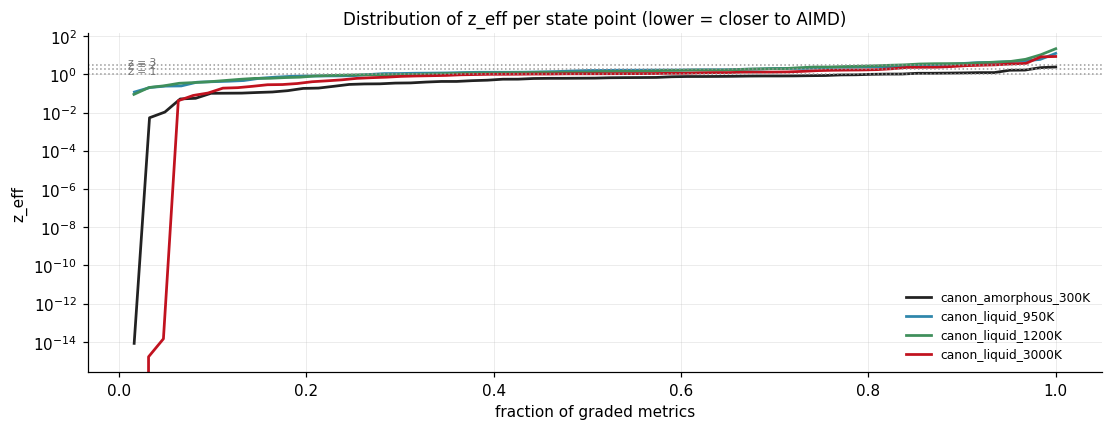

,state,metric_id,value,sigma_ref,z_eff,grade
195,canon_liquid_1200K,L3b.rings.size6,1.3586,0.0018,21.7353,F
118,canon_liquid_950K,L3a.homopolar.Te,0.0896,0.0012,12.4232,F
188,canon_liquid_1200K,L3a.homopolar.Te,0.1109,0.0009,10.4599,F
211,canon_liquid_3000K,L3a.rdf.Ge-Ge.g_peak,2.1761,0.0398,8.5395,F
212,canon_liquid_3000K,L3a.rdf.Ge-Ge.fwhm,0.9000,0.0204,8.1650,F
153,canon_liquid_1200K,L3a.rdf.Ge-Te.wasserstein1,0.0203,0.0033,6.0783,F
122,canon_liquid_950K,L3b.rings.size3,0.4176,0.0057,5.9966,F
119,canon_liquid_950K,L3a.homopolar.total,0.1620,0.0051,5.0167,F
192,canon_liquid_1200K,L3b.rings.size3,0.5859,0.0046,4.6868,F
128,canon_liquid_950K,L3b.rings.size9,0.1019,0.0034,4.5532,F


In [18]:
from mlipeval.models import current_key

STATES_L3 = ["canon_amorphous_300K", "canon_liquid_950K", "canon_liquid_1200K", "canon_liquid_3000K"]
records = []
for name in STATES_L3:
    for level in ("L3a", "L3b"):
        path = paths.result_path(f"{level}_{name}__lammps.json")
        if not path.exists():
            continue
        for r in json.loads(path.read_text())["results"]:
            records.append({"state": name, "level": level, "metric_id": r["metric_id"].split("@")[0],
                            "grade": r["grade"], "status": r["status"], "z_eff": r["z_eff"],
                            "value": r["value"], "sigma_ref": r["uncertainty"]})
graded = pd.DataFrame(records)
print(f"模型 {current_key()}：{len(graded)} 条 L3 metric，{graded.grade.isin(list('ABCF')).sum()} 条判级")
display(pd.crosstab([graded.state, graded.level], graded.grade).reindex(
    columns=[g for g in ("A", "B", "C", "F", "ungraded") if g in set(graded.grade)]))

fig, ax = plt.subplots(figsize=(10, 3.8))
colors = {"canon_amorphous_300K": "#222222", "canon_liquid_950K": "#2e86ab",
          "canon_liquid_1200K": "#3f8f5b", "canon_liquid_3000K": "#c1121f"}
for name in STATES_L3:
    z = graded[(graded.state == name) & graded.z_eff.notna()].z_eff.astype(float).sort_values().values
    if len(z):
        ax.plot(np.arange(1, len(z) + 1) / len(z), z, lw=1.8, color=colors[name], label=name)
for thr, lab in ((1.0, "z = 1"), (2.0, "z = 2"), (3.0, "z = 3")):
    ax.axhline(thr, color="#999", ls=":", lw=1.0)
    ax.text(0.01, thr * 1.05, lab, fontsize=7, color="#777")
ax.set_yscale("log"); ax.set_xlabel("fraction of graded metrics"); ax.set_ylabel("z_eff")
ax.set_title("Distribution of z_eff per state point (lower = closer to AIMD)")
ax.legend(fontsize=8)
plt.show()

worst = graded[graded.z_eff.notna()].sort_values("z_eff", ascending=False).head(12)
display(worst[["state", "metric_id", "value", "sigma_ref", "z_eff", "grade"]].round(4))

（读表结论在执行后填写。）

## 7. 液态状态点：处方在高温下会退化

同一套流程换到 3000 K 液态，会碰到一个真实的问题：**"逐状态点取 partial RDF 第一极小"
这条处方在高温下退化**。各壳层已经并到一起，多数 partial 被判为"无良定义极小"，
回退到总 RDF 的极小——而那个位置早已越过第一壳层，得到的"配位数"其实是第二壳层计数。

代码不会悄悄接受这个结果：`freeze_params_from_reference` 逐对报告 `depth` 与是否回退，
`run_l3.py` 在过半数对回退时打印警告并提示改用 `--cutoffs-from`。三个液体状态点的
正式结果都用 `--cutoffs-from canon_amorphous_300K`。下面把两种做法在 3000 K 上并排跑一遍。

In [19]:
state_l = "canon_liquid_3000K"
st_l = get_state(state_l)
seg_l = production_segments(state_l)

# (a) 按框架处方：就地从液态自己的 RDF 取第一极小
params_own, rdf_l = freeze_params_from_reference(seg_l["reference"], stride=st_l.l3_stride,
                                                 peak_rule=st_l.peak_rule)
diag_own = pd.DataFrame(params_own.cutoff_diagnostics).T
diag_own["cutoff (A)"] = [params_own.bond_cutoffs.get(k, np.nan) for k in diag_own.index]
print("(a) 液态就地推导的截断：")
display(diag_own[["r_peak", "r_min", "depth", "well_defined", "source", "cutoff (A)"]].round(3))
n_fallback = sum(1 for k, v in params_own.cutoff_diagnostics.items()
                 if k != "_total" and not v["well_defined"])
print(f"    {n_fallback}/{len(params_own.bond_cutoffs)} 对回退")

# (b) 从等温非晶末态继承截断，并显式声明这个选择（run_l3 --cutoffs-from 的做法）
params_inh, _ = frozen_params(CUTOFF_STATE)
print(f"\n(b) 从 {CUTOFF_STATE} 继承的截断：",
      {k: round(v, 3) for k, v in sorted(params_inh.bond_cutoffs.items())})

(a) 液态就地推导的截断：


,r_peak,r_min,depth,well_defined,source,cutoff (A)
_total,2.9375,4.4625,0.465383,False,NaN,NaN
Ge-Ge,2.6625,4.2625,0.536499,True,partial RDF first minimum,4.262
Ge-Sb,2.8375,4.1125,0.536284,True,partial RDF first minimum,4.113
Ge-Te,2.7625,4.3125,0.563494,True,partial RDF first minimum,4.312
Sb-Sb,2.9875,4.3125,0.582804,True,partial RDF first minimum,4.312
Sb-Te,2.9875,4.4625,0.483308,False,fallback: total RDF first minimum (partial minimum ill-d...,4.462
Te-Te,3.1375,4.4875,0.307392,False,fallback: total RDF first minimum (partial minimum ill-d...,4.462


    2/6 对回退

(b) 从 canon_amorphous_300K 继承的截断： {'Ge-Ge': 3.163, 'Ge-Sb': 3.213, 'Ge-Te': 3.538, 'Sb-Sb': 3.463, 'Sb-Te': 3.888, 'Te-Te': 3.188}


把两套截断分别应用到同一对轨迹上，差别一目了然。

In [20]:
rows = []
for label, prm in (("(a) in-place", params_own), ("(b) inherited from 300 K glass", params_inh)):
    rep = analyse_short_range(seg_l["reference"], prm, model_traj=seg_l["model"],
                              stride=st_l.l3_stride, model_stride=st_l.l3_stride, state_label=state_l)
    cnv = rep.cn_ref["cn_values"]
    row = {"截断来源": label, "max cutoff (A)": max(prm.bond_cutoffs.values())}
    for sp in ["Ge", "Sb", "Te", "all"]:
        row[f"<CN> {sp} AIMD"] = float(np.sum(cnv * rep.cn_ref[sp]))
        row[f"<CN> {sp} MLIP"] = float(np.sum(cnv * rep.cn_model[sp]))
    rows.append(row)
    if label.startswith("(b)"):
        l3a_l = rep
display(pd.DataFrame(rows).round(3))

,截断来源,max cutoff (A),<CN> Ge AIMD,<CN> Ge MLIP,<CN> Sb AIMD,<CN> Sb MLIP,<CN> Te AIMD,<CN> Te MLIP,<CN> all AIMD,<CN> all MLIP
0,(a) in-place,4.462,9.593,9.583,10.102,10.142,10.582,10.506,10.256,10.220
1,(b) inherited from 300 K glass,3.888,4.942,4.947,5.946,5.953,4.131,4.166,4.714,4.736


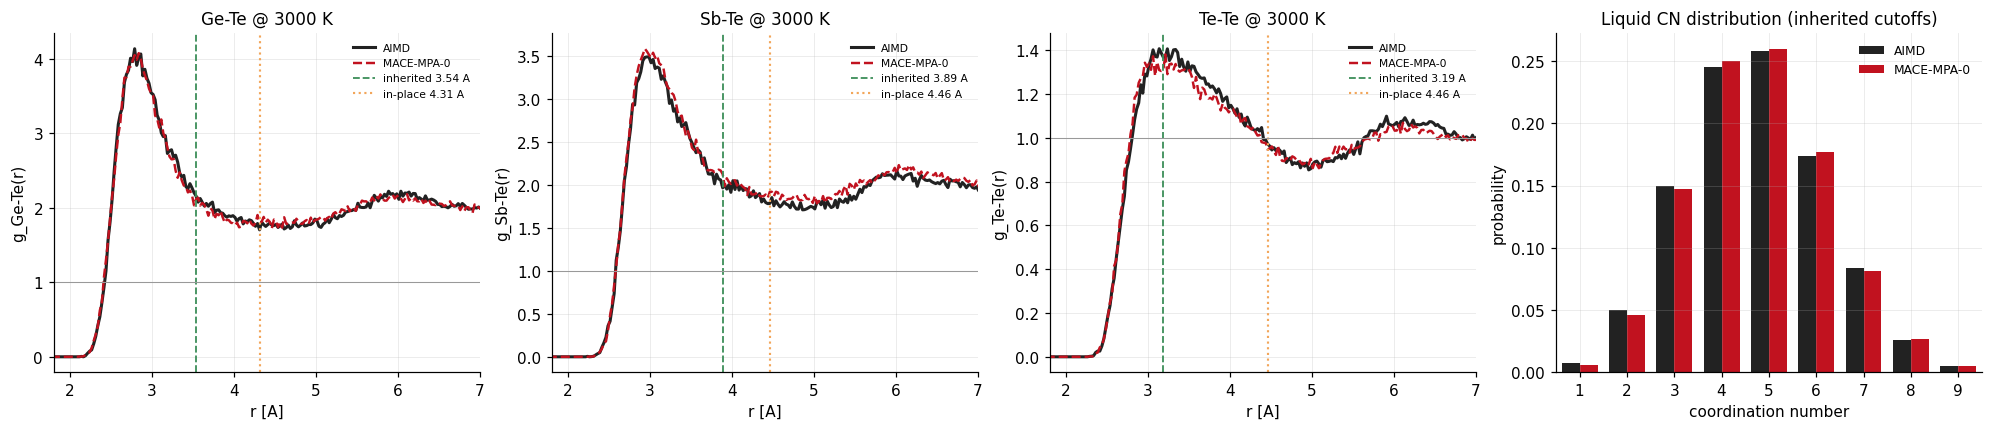

,metric_id,value,reference
0,L3a.cn.Ge.mean,4.9466,4.9417
1,L3a.cn.Ge.jensen_shannon,0.0184,NaN
2,L3a.cn.Sb.mean,5.9530,5.9457
3,L3a.cn.Sb.jensen_shannon,0.0149,NaN
4,L3a.cn.Te.mean,4.1656,4.1309
5,L3a.cn.Te.jensen_shannon,0.0170,NaN
6,L3a.cn.all.mean,4.7364,4.7144
7,L3a.cn.all.jensen_shannon,0.0144,NaN
8,L3a.homopolar.Ge,0.0406,0.0392
9,L3a.homopolar.Sb,0.0480,0.0525


In [21]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
r = l3a_l.rdf_ref["r"]
for ax, key in zip(axes[:3], ["Ge-Te", "Sb-Te", "Te-Te"]):
    ax.plot(r, l3a_l.rdf_ref[key], color="#222222", lw=2.0, label="AIMD")
    ax.plot(r, l3a_l.rdf_model[key], color="#c1121f", lw=1.6, ls="--", label="MACE-MPA-0")
    ax.axvline(params_inh.bond_cutoffs[key], color="#3f8f5b", ls="--", lw=1.2,
               label=f"inherited {params_inh.bond_cutoffs[key]:.2f} A")
    ax.axvline(params_own.bond_cutoffs[key], color="#f2a65a", ls=":", lw=1.4,
               label=f"in-place {params_own.bond_cutoffs[key]:.2f} A")
    ax.axhline(1.0, color="#999", lw=0.7); ax.set_xlim(1.8, 7.0)
    ax.set_xlabel("r [A]"); ax.set_ylabel(f"g_{key}(r)"); ax.set_title(f"{key} @ {st_l.temperature_k:.0f} K")
    ax.legend(fontsize=7)

cnv = l3a_l.cn_ref["cn_values"]
w = 0.38
axes[3].bar(cnv - w / 2, l3a_l.cn_ref["all"], w, color="#222222", label="AIMD")
axes[3].bar(cnv + w / 2, l3a_l.cn_model["all"], w, color="#c1121f", label="MACE-MPA-0")
axes[3].set_xlim(0.5, 9.5); axes[3].set_xlabel("coordination number"); axes[3].set_ylabel("probability")
axes[3].set_title("Liquid CN distribution (inherited cutoffs)"); axes[3].legend(fontsize=8)
plt.show()

display(pd.DataFrame([{"metric_id": r.metric_id.split("@")[0], "value": r.value,
                       "reference": (r.extra or {}).get("reference")}
                      for r in l3a_l.results
                      if ".cn." in r.metric_id or "homopolar" in r.metric_id
                      or "tetrahedral" in r.metric_id]).round(4))

## 8. 误差尺度：哪些差异是可分辨的

第 6 节的 `sigma_ref` 回答"AIMD 链与链之间本来差多少"。这一节补两个**模型侧**的尺度，
回答"当前的轨迹长度能分辨什么"：

| 尺度 | 怎么测 | 回答什么问题 |
|---|---|---|
| **分块 SEM** | 把一条轨迹切成连续块，逐块算观测量，取块间均值的标准误 | 这个数收敛了吗？ |
| **种子散布** | 同一模型换随机种子再跑，比较三条 | 同一个模型自己就会差这么多吗？ |

用连续块而不是随机抽样，是因为 MD 帧强烈自相关——随机抽样会把相关帧当成独立样本，
严重低估误差。种子散布还要加一个下限：链间散布不可能小于各自的统计误差，
所以用 `有效散布 = max(种子散布, 合并 SEM)`。这一节不出等级，只做可分辨性分类；
`run_l3_uncertainty.py` 对每个状态点都写一份同样的分类。

In [22]:
from mlipeval.uncertainty import (
    VERDICTS, block_estimates, compare_with_uncertainty, l3_scalars, seed_scatter_from,
)

state_u = "canon_amorphous_300K"
seg_u = production_segments(state_u)
params_u, _ = frozen_params(state_u)
seeds = STATES[state_u].available_seeds()
print("可用的 MLIP 种子:", seeds)

kw = dict(stride=2, ring_stride=5)          # run_l3_uncertainty.py defaults
ref_est = block_estimates(seg_u["reference"], params_u, n_blocks=5, **kw)
mod_est = block_estimates(seg_u["model"], params_u, n_blocks=5, **kw)

scatter = None
if len(seeds) > 1:
    others = [block_estimates(production_segments(state_u, seed=s)["model"], params_u, n_blocks=5, **kw)
              for s in seeds[1:]]
    scatter = seed_scatter_from([mod_est, *others])

comparisons = compare_with_uncertainty(ref_est, mod_est, seed_scatter=scatter,
                                       n_seeds=len(seeds), z_threshold=2.0)
u = pd.DataFrame([c.to_dict() for c in comparisons])
print(f"\n共 {len(u)} 个标量观测量")
display(u.verdict.value_counts().to_frame("数量"))
for k, v in VERDICTS.items():
    if k in set(u.verdict):
        print(f"  {k}: {v}")

可用的 MLIP 种子: [0, 1, 2]

共 33 个标量观测量


,数量
verdict,
within_seed_scatter,16
within_statistical_noise,15
resolved,2


  resolved: |difference| exceeds both the combined block SEM (x z_threshold) and the model's own seed-to-seed scatter: a real difference at the available statistics
  within_statistical_noise: |difference| is not larger than the combined block SEM: the trajectories are too short to say the two sides differ at all
  within_seed_scatter: |difference| is statistically significant but no larger than what the same model produces by changing only its random seed (scatter floored by the combined SEM): not attributable to model error


### 三档判定的分布

`resolved` 才是可以拿去下结论的；`within_seed_scatter` 是统计显著但**不可归因**；
`within_statistical_noise` 是轨迹太短、根本还没测出来。

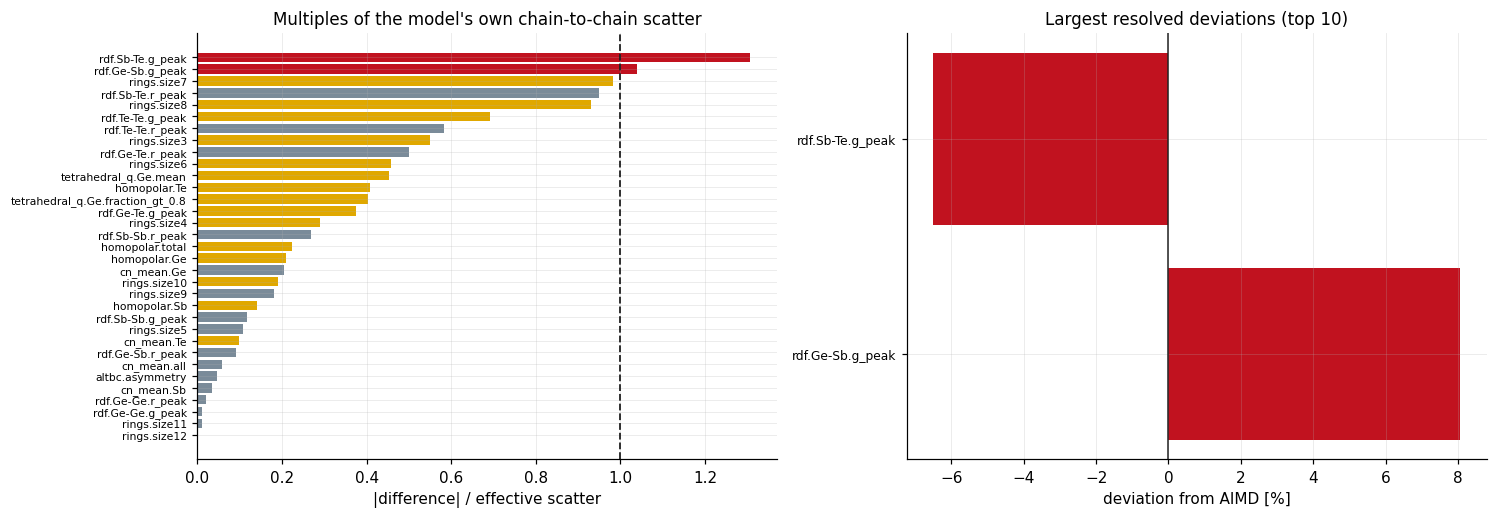

,observable,reference_mean,reference_sem,model_mean,model_sem,difference,z_statistical,effective_scatter,seed_ratio,verdict
17,rdf.Sb-Te.g_peak,10.45344,0.19441,9.77437,0.07508,-0.67907,3.25843,0.52011,1.30563,resolved
11,rdf.Ge-Sb.g_peak,4.02104,0.10753,4.34562,0.07092,0.32458,2.51973,0.31243,1.03890,resolved
28,rings.size7,0.43623,0.00563,0.51041,0.00188,0.07418,12.50271,0.07554,0.98208,within_seed_scatter
18,rdf.Sb-Te.r_peak,2.92750,0.01275,2.94250,0.00935,0.01500,0.94868,0.01581,0.94868,within_statistical_noise
29,rings.size8,0.36438,0.00632,0.32325,0.00416,-0.04113,5.43884,0.04421,0.93031,within_seed_scatter
19,rdf.Te-Te.g_peak,2.67472,0.02187,2.80308,0.04012,0.12836,2.80897,0.18539,0.69240,within_seed_scatter
20,rdf.Te-Te.r_peak,4.16750,0.02424,4.13250,0.01458,-0.03500,1.23744,0.06000,0.58333,within_statistical_noise
24,rings.size3,0.11555,0.00272,0.10528,0.00296,-0.01027,2.55572,0.01867,0.55000,within_seed_scatter
14,rdf.Ge-Te.r_peak,2.79750,0.00612,2.78750,0.00791,-0.01000,1.00000,0.02000,0.50000,within_statistical_noise
27,rings.size6,1.76060,0.02372,1.64001,0.00910,-0.12059,4.74661,0.26391,0.45693,within_seed_scatter


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

order = u.sort_values("seed_ratio", ascending=True)
order = order[order.seed_ratio.notna()]
colors = {"resolved": "#c1121f", "within_seed_scatter": "#e0a800",
          "within_statistical_noise": "#7a8b99", "unavailable": "#cccccc"}
axes[0].barh(np.arange(len(order)), order.seed_ratio,
             color=[colors[v] for v in order.verdict])
axes[0].axvline(1.0, color="#222", ls="--", lw=1.2)
axes[0].set_yticks(np.arange(len(order)))
axes[0].set_yticklabels(order.observable, fontsize=7)
axes[0].set_xlabel("|difference| / effective scatter"); axes[0].set_title("Multiples of the model's own chain-to-chain scatter")

sig = u[u.verdict == "resolved"].sort_values("seed_ratio", ascending=False).head(10)
y = np.arange(len(sig))
rel_ref = np.zeros(len(sig))
rel_mod = (sig.model_mean - sig.reference_mean) / sig.reference_mean.abs() * 100
axes[1].barh(y, rel_mod, color="#c1121f")
axes[1].axvline(0, color="#222", lw=1.0)
axes[1].set_yticks(y); axes[1].set_yticklabels(sig.observable, fontsize=8)
axes[1].invert_yaxis()
axes[1].set_xlabel("deviation from AIMD [%]"); axes[1].set_title("Largest resolved deviations (top 10)")
plt.show()

display(u.sort_values("seed_ratio", ascending=False)[
    ["observable", "reference_mean", "reference_sem", "model_mean", "model_sem",
     "difference", "z_statistical", "effective_scatter", "seed_ratio", "verdict"]
].round(5))

### 按观测量族看，图像很干净

把上表按族归类，模型的行为可以一句话说清。

verdict,resolved,within_seed_scatter,within_statistical_noise
family,,,
ALTBC,0,0,1
Ge tetrahedral order,0,2,0
RDF peak height,2,2,2
bond length (RDF peak position),0,0,6
homopolar fraction,0,4,0
mean coordination number,0,1,3
ring distribution,0,7,3


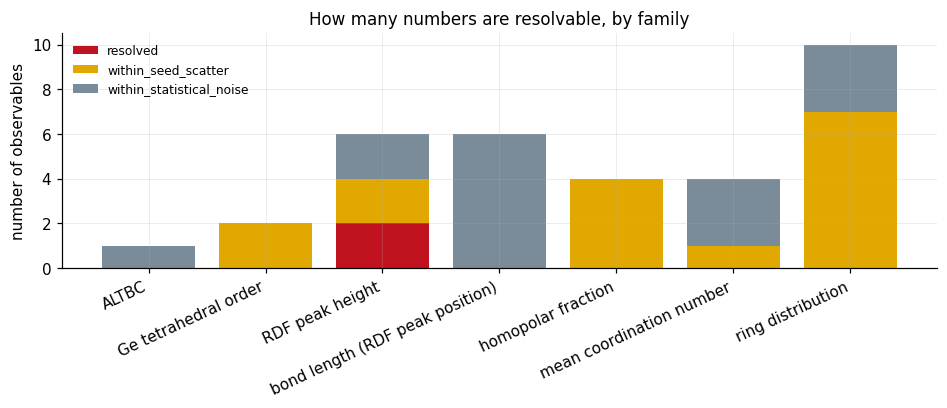

In [24]:
family = []
for _, row in u.iterrows():
    name = row["observable"]
    if name.startswith("rdf.") and name.endswith("r_peak"):
        fam = "bond length (RDF peak position)"
    elif name.startswith("rdf.") and name.endswith("g_peak"):
        fam = "RDF peak height"
    elif name.startswith("cn_mean"):
        fam = "mean coordination number"
    elif name.startswith("homopolar"):
        fam = "homopolar fraction"
    elif name.startswith("rings"):
        fam = "ring distribution"
    elif name.startswith("tetrahedral"):
        fam = "Ge tetrahedral order"
    else:
        fam = "ALTBC"
    family.append(fam)
u["family"] = family

pivot = pd.crosstab(u["family"], u.verdict)
display(pivot)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
bottom = np.zeros(len(pivot))
for verdict in ["resolved", "within_seed_scatter", "within_statistical_noise"]:
    if verdict not in pivot.columns:
        continue
    ax.bar(pivot.index, pivot[verdict], bottom=bottom, label=verdict, color=colors[verdict])
    bottom += pivot[verdict].values
ax.set_ylabel("number of observables"); ax.set_title("How many numbers are resolvable, by family")
ax.legend(fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
plt.show()

**读出来的诊断**

（执行后填写。）

## 小结

（执行后填写。）